**Name**: Frances Elizabeth Redican Ferrabee

**Student ID**: 2141885

**Date**:

# Loading Fashion-MNST

In [1]:
def get_dbn_library():
  files = ["DBN.py", "RBM.py"]
  repository_url = "https://raw.githubusercontent.com/flavio2018/Deep-Belief-Network-pytorch/master/"
  for file in files:
    ! wget -O {file} {repository_url}{file}


In [2]:
get_dbn_library()

--2026-01-13 21:20:19--  https://raw.githubusercontent.com/flavio2018/Deep-Belief-Network-pytorch/master/DBN.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.111.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 6587 (6.4K) [text/plain]
Saving to: ‘DBN.py’

DBN.py              100%[===================>]   6.43K  --.-KB/s    in 0s      

2026-01-13 21:20:19 (79.6 MB/s) - ‘DBN.py’ saved [6587/6587]

--2026-01-13 21:20:19--  https://raw.githubusercontent.com/flavio2018/Deep-Belief-Network-pytorch/master/RBM.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 9785 (9.6K) [text/plain]
Sa

In [3]:
import matplotlib.pyplot as plt
import math
import numpy as np
import pandas as pd
import scipy.cluster as cluster
import sklearn.preprocessing
import torchvision as tv
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader,TensorDataset
import matplotlib.pyplot as plt
import seaborn as sns
from DBN import DBN
from tqdm.notebook import tqdm
import numpy as np
from sklearn.metrics import confusion_matrix


In [4]:
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")


In [5]:
fashion_mnist_tr = tv.datasets.FashionMNIST(root="../fashion_mnist", train=True, download=True)
fashion_mnist_te = tv.datasets.FashionMNIST(root="../fashion_mnist", train=False, download=True)

100%|██████████| 26.4M/26.4M [00:01<00:00, 14.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.76MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 4.37MB/s]


In [6]:
fashion_mnist_tr.data=fashion_mnist_tr.data/255
fashion_mnist_te.data=fashion_mnist_te.data/255

In [7]:
fashion_mnist_tr.data=fashion_mnist_tr.data.to(device)
fashion_mnist_te.data=fashion_mnist_te.data.to(device)

fashion_mnist_tr.targets = fashion_mnist_tr.targets.to(device)
fashion_mnist_te.targets = fashion_mnist_te.targets.to(device)

In [8]:
fashion_mnist_tr.targets

tensor([9, 0, 0,  ..., 3, 0, 5], device='cuda:0')

# **The model**

For my model I chose to use a DBN out of all the potential generative models as it is able to learn hierarchial representations of the data. By stacking multiple RBMs and training each layer using contrastive divergence the model is able to capture more complex patterns from the layer bellow it. This makes it so that the model is better able to disentangle the features from noise. Also DBNs use unsupervised learning to ensure the model learns the structure of the fashion items without needing the labels making it more robust.  I originally experimented with a CNN-DBN hybrid approach but this proved to be a problem when i wanted to do Bottom-up sampling which is required to defend against adversarial attacks.

**Building and training the DBN**

I structured my hidden layers so that they were decreasing each time and would force the model to have to disentangle features as it moved further into the network. for the first layer i chose 800 hidden units so that it is larger then the visible units and would mean the model would be able to capture all the details. For each previous layer I decreases the number of hidden units so that the DBN would not copy information from the previous layer but instead compresses the features into a compact hierarchial representation of the data.

The other parameters such as learning rate,initial momentum and weight_decay were chosen through trial and error.

In [9]:

dbn_fashion_mnist = DBN(

    visible_units = 28*28,

    hidden_units = [800, 700, 400],

    k = 5,

    learning_rate=0.005,
    learning_rate_decay = True,

    initial_momentum=0.5,

    final_momentum = 0.9,

    weight_decay =0.0001,

    xavier_init = True,

    increase_to_cd_k = False,

    use_gpu = torch.cuda.is_available())

I chose to do 40 epochs since a few of the layers start to overfit past this point.

In [10]:
num_epochs = 40
batch_size = 125

dbn_fashion_mnist.train_static(
    fashion_mnist_tr.data,
    fashion_mnist_tr.targets,
    num_epochs,
    batch_size
)

--------------------
Training RBM layer 1
|Epoch |avg_rec_err |std_rec_err  |mean_grad |std_grad  |
|10    |4.4467     |0.1795       |3.7988   |0.1984     |
|20    |4.1700     |0.1727       |1.8427   |0.0982     |
|30    |4.0630     |0.1599       |1.2348   |0.0790     |
|40    |4.0055     |0.1602       |0.9250   |0.0466     |
--------------------
Training RBM layer 2
|Epoch |avg_rec_err |std_rec_err  |mean_grad |std_grad  |
|10    |1.3461     |0.0559       |2.4692   |0.1519     |
|20    |1.2140     |0.0510       |1.1298   |0.0941     |
|30    |1.1781     |0.0494       |0.7199   |0.0558     |
|40    |1.1585     |0.0507       |0.5213   |0.0407     |
--------------------
Training RBM layer 3
|Epoch |avg_rec_err |std_rec_err  |mean_grad |std_grad  |
|10    |1.2648     |0.0569       |1.5262   |0.0892     |
|20    |1.0900     |0.0463       |0.6249   |0.0439     |
|30    |1.0488     |0.0468       |0.3868   |0.0280     |
|40    |1.0343     |0.0489       |0.2932   |0.0218     |


After training the model in the unsupervised DBN, i chose to do some supervised fine tuning. I did this so that the model was better able to differentiate the different labels. In DBN the model does not have access to the labels, the goal is to sort the data into a hierarchy with increasingly more complex features unaware of these labels. Now by introducing the labels I was able to use backpropagation to refine the weights further.

I decided to add dropout between layers. This was to help the model to not overfit and to rally less on specific neurons.

In [11]:

class Noisey_vals(nn.Module):
  def __init__(self,level=0.1):
    super().__init__()
    self.level = level
  def forward(self, x):
    if self.training:
      return x + torch.randn_like(x) * self.level
    return x

class FullModel(nn.Module):
    def __init__(self, dbn):
        super().__init__()
        dbn_vals = []
        for indx, rbm in enumerate(dbn.rbm_layers):
            in_dim, out_dim = rbm.W.shape
            layer = nn.Linear(in_dim, out_dim)
            layer.weight.data = rbm.W.t().clone()
            layer.bias.data = rbm.h_bias.clone()

            if indx == 0:
                noise = Noisey_vals(0.15)
                dropout = nn.Dropout(0.2)
            elif indx == 1:
                noise = Noisey_vals(0.10)
                dropout = nn.Dropout(0.15)
            else:
                noise = Noisey_vals(0.05)
                dropout =  nn.Dropout(0)

            dbn_vals.extend([
                layer,
                noise,
                nn.LeakyReLU(0.1),
                dropout
            ])

        self.dbn = nn.Sequential(*dbn_vals)

        self.classifier = nn.Linear(out_dim, 10)

    def forward(self, x):
        x = self.dbn(x)
        return self.classifier(x)



model_full = FullModel(dbn_fashion_mnist).to(device)


model_full = FullModel(dbn_fashion_mnist).to(device)

To fine tune the model, I only ran the model for 10 epochs at a fairly low learning rate. I did this to prevent the fine tuning process from completely overwriting the representations learned from the DBN during unsupervised learning. My goal in doing this was to perserve the structure found during unsupervised learning while improving the models ability to differentiate between different labels.

In [12]:
def fine_tune(model, loader, epochs=10, lr=5e-4):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()

    model.train()
    for epoch in range(epochs):
        totalLoss = 0.0

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            images = images.view(images.size(0), -1)
            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_fn(outputs, labels)

            loss.backward()
            optimizer.step()

            totalLoss += loss.item()

        avgloss = totalLoss / len(loader)
        print(f"Epoch {epoch+1}/{epochs} | Loss: {avgloss:.4f}")


loader = DataLoader(TensorDataset(fashion_mnist_tr.data, fashion_mnist_tr.targets), batch_size=128, shuffle=True)
fine_tune(model_full, loader)

Epoch 1/10 | Loss: 0.8436
Epoch 2/10 | Loss: 0.4025
Epoch 3/10 | Loss: 0.3565
Epoch 4/10 | Loss: 0.3311
Epoch 5/10 | Loss: 0.3090
Epoch 6/10 | Loss: 0.2968
Epoch 7/10 | Loss: 0.2826
Epoch 8/10 | Loss: 0.2721
Epoch 9/10 | Loss: 0.2608
Epoch 10/10 | Loss: 0.2520


to get the hidden representation from the DBN at each layer I created this function. I also made it so that the function accepts raw image data and automatically puts in through its layer of the fine-tuned DBN.

In [13]:
def get_kth_layer_repr(input_data, k, device):

  model_full.eval()
  with torch.no_grad():
    if input_data.dim() > 2:
      x = input_data.view(input_data.size(0), -1).to(device)

    else:
      x = input_data.to(device)

  layer_block = model_full.dbn[k*4 : k*4+4]
  with torch.no_grad():
    hidden_repr = layer_block(x)

  return hidden_repr





In [14]:
hidden_repr_1 = get_kth_layer_repr(fashion_mnist_tr.data, 0, device).detach()
hidden_repr_2 = get_kth_layer_repr(hidden_repr_1, 1, device).detach()
hidden_repr_3 = get_kth_layer_repr(hidden_repr_2, 2, device).detach()

# **Linear Read-out**

A simple linear classifier is used to classify the fashion MNIST images. I added batch normalization so that the values are at the same scale before classification.

In [15]:
class LinearModel(torch.nn.Module):
  def __init__(self, layer_size):
    super().__init__()
    self.linear = torch.nn.Linear(layer_size, 10)
    self.bn= torch.nn.BatchNorm1d(layer_size)
  def forward(self, x):
    x= self.bn(x)
    return self.linear(x)

We have a linear classifier for each level of the DBN

In [16]:
layer_size = dbn_fashion_mnist.rbm_layers[0].W.shape[1]
linear1 = LinearModel(layer_size).to(device)

layer_size = dbn_fashion_mnist.rbm_layers[1].W.shape[1]
linear2 = LinearModel(layer_size).to(device)

layer_size = dbn_fashion_mnist.rbm_layers[2].W.shape[1]
linear3 = LinearModel(layer_size).to(device)

I trained a linear classifier on each level of the DBN, I included regularization such as early stopping ,where if the patience reaches a certain number it stops completely ,and weight decay. The regularization was done to prevent overfitting and makes sure that the model converges in an efficient way.

In [17]:
def train_linear(linear, hidden_reprs):
  optimizer = torch.optim.Adam(linear.parameters(), lr=0.01,weight_decay=0.0005)

  loss_fn = torch.nn.CrossEntropyLoss()
  epochs =2000
  bestloss= float('inf')
  improve_count = 0
  linear.train()
  hidden_reprs = hidden_reprs.to(device)
  for epoch in range(epochs):

    optimizer.zero_grad()

    predictions = linear(hidden_reprs).squeeze()
    targets = fashion_mnist_tr.targets.reshape(predictions.shape[0])
    loss = loss_fn(predictions, targets)
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
      print("epoch : {:3d}/{}, loss = {:.4f}".format(epoch + 1, epochs, loss))

    if loss.item() + 0.0001 < bestloss:
      improve_count = 0
      bestloss = loss.item()

    else:
      improve_count += 1

    if improve_count >= 10:
      print(f"Converged early at epoch {epoch}. Best loss: {bestloss:.4f}")
      break

In [18]:
train_linear(linear1, hidden_repr_1)

epoch :   1/2000, loss = 2.2608
epoch : 101/2000, loss = 0.2474
epoch : 201/2000, loss = 0.2372
epoch : 301/2000, loss = 0.2305
epoch : 401/2000, loss = 0.2265
epoch : 501/2000, loss = 0.2241
epoch : 601/2000, loss = 0.2225
Converged early at epoch 642. Best loss: 0.2221


In [19]:
train_linear(linear2, hidden_repr_2)

epoch :   1/2000, loss = 2.4659
epoch : 101/2000, loss = 0.2271
epoch : 201/2000, loss = 0.2214
epoch : 301/2000, loss = 0.2170
epoch : 401/2000, loss = 0.2144
Converged early at epoch 456. Best loss: 0.2135


In [20]:
train_linear(linear3, hidden_repr_3)

epoch :   1/2000, loss = 2.4381
epoch : 101/2000, loss = 0.2202
epoch : 201/2000, loss = 0.2130
epoch : 301/2000, loss = 0.2090
epoch : 401/2000, loss = 0.2067
epoch : 501/2000, loss = 0.2053
Converged early at epoch 547. Best loss: 0.2049


I got the hidden representations for the test set and then fed these through the linear model to get the predictions.

In [21]:
hidden_repr_1_test = get_kth_layer_repr(fashion_mnist_te.data, 0, device)
hidden_repr_2_test = get_kth_layer_repr(hidden_repr_1_test, 1, device)
hidden_repr_3_test = get_kth_layer_repr(hidden_repr_2_test, 2, device)

In [22]:
predictions_test1 = linear1(hidden_repr_1_test)
predictions_test2 = linear2(hidden_repr_2_test)
predictions_test3 = linear3(hidden_repr_3_test)


compute accuracy of each linear read out

In [23]:
def compute_accuracy(predictions_test, targets):
  predictions_indices = predictions_test.max(axis=1).indices
  accuracy = (predictions_indices == targets).sum() / len(targets)
  return accuracy.item()

In [24]:
compute_accuracy(predictions_test1, fashion_mnist_te.targets)

0.8919999599456787

In [25]:
compute_accuracy(predictions_test2, fashion_mnist_te.targets)

0.8922999501228333

In [26]:
compute_accuracy(predictions_test3, fashion_mnist_te.targets)

0.8944999575614929

**Linear readout**
**Conclusion**: To assess if sensory representation became increasingly more disentangled as the layers got deeper I trained a linear classifier on each level of the RBM. My results showed that my classification accuracy increased slightly as the layers increased. This slight increase in accuracy in the deeper layers partially proves disentanglement and indicates that the deeper layers are able to extract important and more detailed features then shallower ones.

But also the the fact that the hidden units are decreasing as the accuracy is increasing further proves disentanglement since this means that the model was able to express the same information with significantly less hidden units without losing any linear seperability. Which indicates that the deeper layers are able to extract important features while discarding unimportant ones.





# **Exploiting hierarchical clustering and feature visualization**

**visualizing the receptive fields**

To visualize the receptive fields i performed many steps. The first thing i did was i applied a small threshold to the weights to remove noise, then I scaled the weights so that they are meaningful across different receptive fields, and finally i plotted the receptive fields.

In [27]:
def get_weights(dbn, layer):
  return dbn.rbm_layers[layer].W.detach().cpu().numpy()

def apply_threshold(weights, threshold=0):
  return weights * (abs(weights) > threshold)

def apply_min_max_scaler(learned_weights):
  original_shape = learned_weights.shape
  min_max_scaler = sklearn.preprocessing.MinMaxScaler()
  min_max_scaled_learned_weights = min_max_scaler.fit_transform(learned_weights.ravel().reshape(-1,1))
  min_max_scaled_learned_weights = min_max_scaled_learned_weights.reshape(original_shape)
  return min_max_scaled_learned_weights

def plot_layer_receptive_fields(weights):
  num_subplots = 100
  n_rows_cols = int(math.sqrt(num_subplots))
  fig, axes = plt.subplots(n_rows_cols, n_rows_cols, sharex=True, sharey=True, figsize=(10, 10))
  for i in range(num_subplots):
    row = i % n_rows_cols
    col = i // n_rows_cols
    axes[row, col].imshow(weights[i,:].reshape((28,28)), cmap=plt.cm.gray)




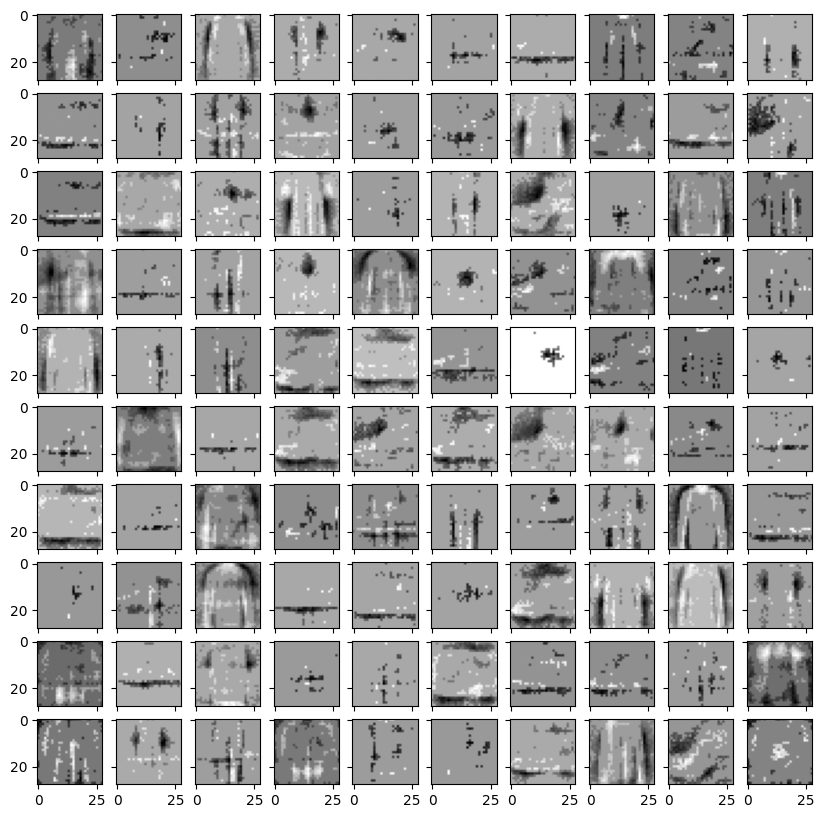

In [28]:

w1 = get_weights(dbn_fashion_mnist, layer=0)
w1 = apply_threshold(w1, 0.05)
w1 = apply_min_max_scaler(w1)

plot_layer_receptive_fields(w1.T)


we can see that in the first hidden layer there are a lot of lines which look that look like basic outlines of clothing, but also a lot of noise.

We have to project the 2nd and 3rd hidden layers since they dont have the same dimension as the Fashion MNIST

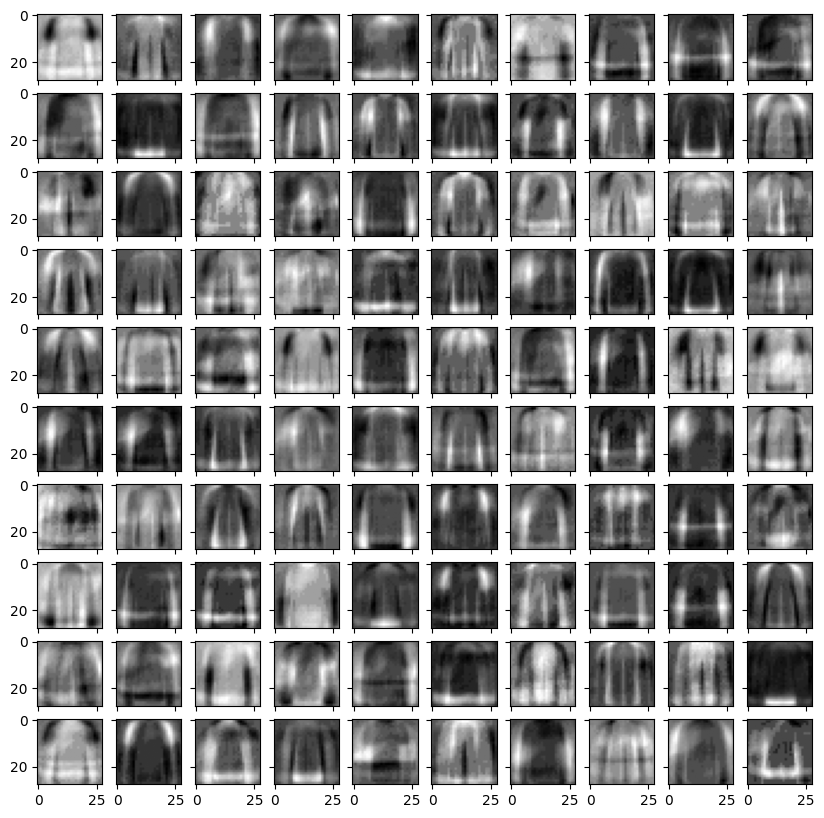

In [29]:
w1 = get_weights(dbn_fashion_mnist, layer=0)
w2 = get_weights(dbn_fashion_mnist, layer=1)


w1 = apply_threshold(w1, 0.05)
w2 = apply_threshold(w2,0.05)

w_product = (w1 @ w2)
w_product = apply_threshold(w_product, 0.05)
w_product = apply_min_max_scaler(w_product)

plot_layer_receptive_fields(w_product.T)


In the second layer we can see more clear outlines of some of the items,but there is still quite a bit of noise.

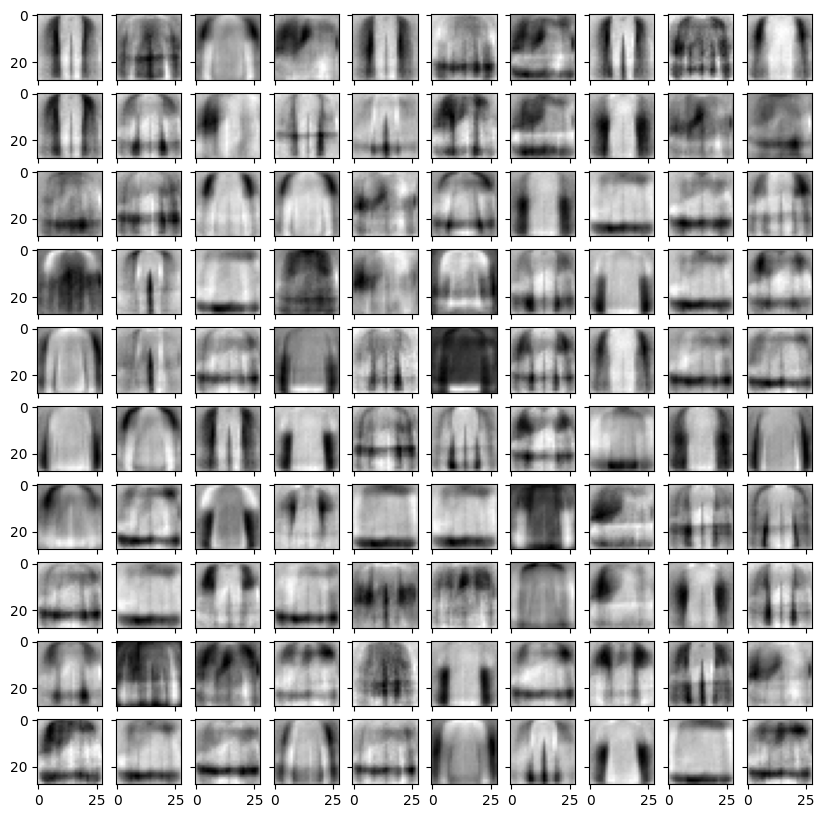

In [30]:
w1 = get_weights(dbn_fashion_mnist, layer=0)
w2 = get_weights(dbn_fashion_mnist, layer=1)
w3 = get_weights(dbn_fashion_mnist, layer=2)

w1 = apply_threshold(w1, 0.05)
w2 = apply_threshold(w2, 0.05)
w3 = apply_threshold(w3, 0.05)

w_product_12 = (w1 @ w2)  # here we do the projection
w_product_23 = (w_product_12 @ w3)  # here we do the projection
w_product_23 = apply_threshold(w_product_23, 0.05)
w_product_23 = apply_min_max_scaler(w_product_23)

plot_layer_receptive_fields(w_product_23.T)

In the final layer the items are more clear then the two previous layers. There are some details so its easier for a person to be able to tell the difference between items.

**hierarchial Clustering**


In [31]:
def get_mask(label):
  labels = fashion_mnist_tr.targets.cpu().numpy()
  return labels == label

def get_label_to_mean_hidd_repr(hidden_repr):
  hidden_repr_np = hidden_repr.cpu().numpy()
  return {
    label: hidden_repr_np[get_mask(label)].mean(axis=0)
    for label in range(10)
  }

def get_hidden_reprs_matrix(hidden_repr):
  label_to_mean_hidd_repr = get_label_to_mean_hidd_repr(hidden_repr)
  return np.concatenate(
    [np.expand_dims(label_to_mean_hidd_repr[label], axis=0)
    for label in range(10)])





In [32]:
mean_hidd_repr_matrix_1 = get_hidden_reprs_matrix(hidden_repr_1)
mean_hidd_repr_matrix_2 = get_hidden_reprs_matrix(hidden_repr_2)
mean_hidd_repr_matrix_3 = get_hidden_reprs_matrix(hidden_repr_3)

we run the clustering algorithm and visualize the output in a dendrogram plot.

In [33]:
def plot_dendrogram(mean_repr_matrix, title=""):
  fig, ax = plt.subplots()
  linkage = cluster.hierarchy.linkage(mean_repr_matrix, method="complete")
  dendrogram = cluster.hierarchy.dendrogram(linkage)
  ax.set_title(title)

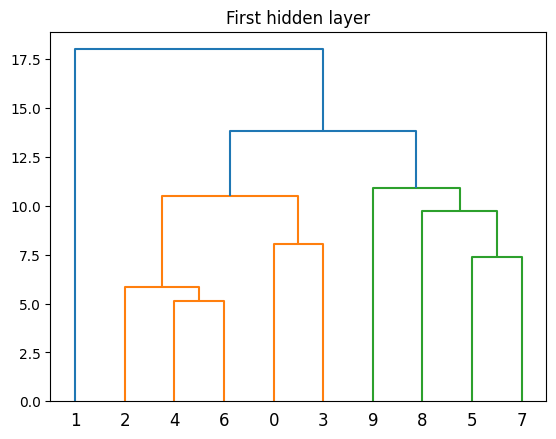

In [34]:
plot_dendrogram(mean_hidd_repr_matrix_1, "First hidden layer")


In [35]:
for indx, class_name in enumerate(fashion_mnist_tr.classes):
    print(f"{indx}: {class_name}")

0: T-shirt/top
1: Trouser
2: Pullover
3: Dress
4: Coat
5: Sandal
6: Shirt
7: Sneaker
8: Bag
9: Ankle boot



We can see from the dendrogram that the first layer of the DBN starts arranging the clothing based on geometric similarities. For example 4 (Coat), 2 (pullover) and 6 (Shirt) are grouped closely together and suggests that the first layer has extracted the long rectangular shape that these objects have in common. However 9 (ankle boot) is placed close to 8 (bag) which shows that the first layer misses a lot of details.





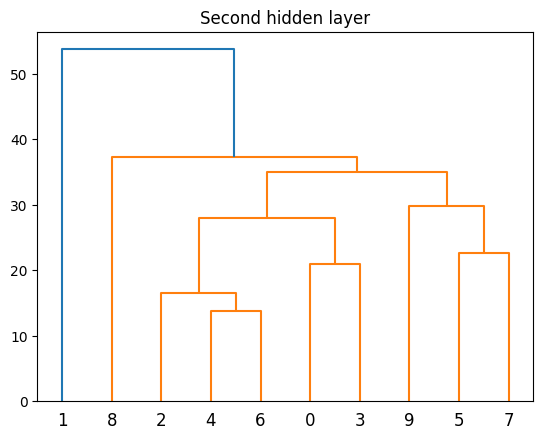

In [36]:
plot_dendrogram(mean_hidd_repr_matrix_2, "Second hidden layer")


In the second layer, we see that the model corrects the errors made in the first hidden layer. 8 (Bag) which was previously placed close to 9 (Ankle boot) now has its own branch far from all other clothing. This indicates that the second layer is able to learn object categories better then the first layer.

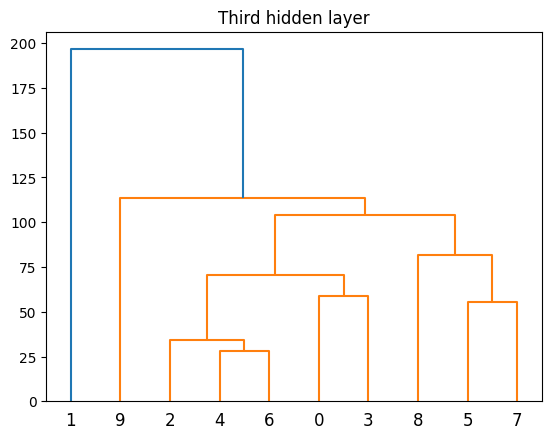

In [37]:
plot_dendrogram(mean_hidd_repr_matrix_3, "Third hidden layer")


In the final layer the model has the highest ability to distinguish objects. The classes are now seperated by significantly longer distances then the first and second hidden layers which indicates that the model is able to seperate the objects better.

# **confusion matrices and psychometric curves**

**Confusion Matrices**

this is my function to get the confusion matrix, my predictions and targets have to be transformed to be able to use the confusion_matrix function form sklearn

In [38]:
def get_confusion_matrix(predictions, targets):
    preds = predictions.argmax(dim=1).cpu().numpy()
    targs = targets.cpu().numpy()
    return confusion_matrix(targs, preds)

In [39]:
confusion_matrix1 = get_confusion_matrix(predictions_test1, fashion_mnist_te.targets)
confusion_matrix2 = get_confusion_matrix(predictions_test2, fashion_mnist_te.targets)
confusion_matrix3 = get_confusion_matrix(predictions_test3, fashion_mnist_te.targets)

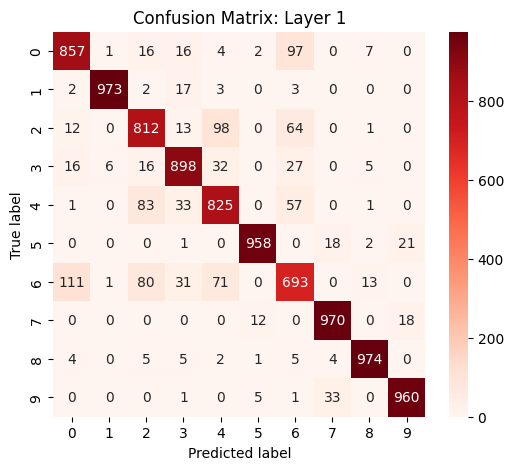

In [40]:

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix1,annot=True,fmt="d",cmap="Reds")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix: Layer 1")
plt.show()

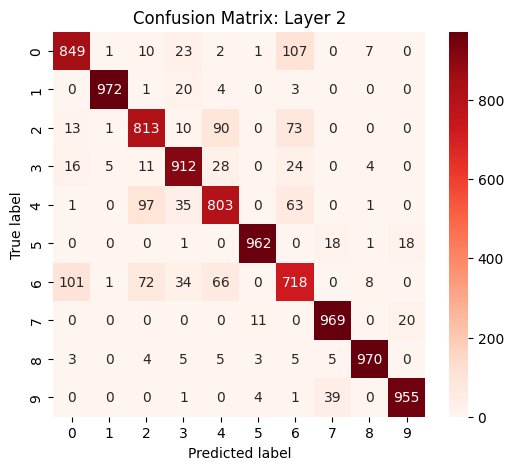

In [41]:

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix2,annot=True,fmt="d",cmap="Reds")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix: Layer 2")
plt.show()

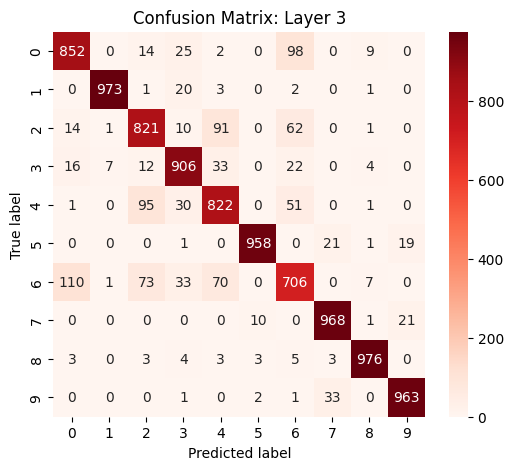

In [42]:

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix3,annot=True,fmt="d",cmap="Reds")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix: Layer 3")
plt.show()

The confusion matrices for the three layers all look very similar however we can see that the incorrect values decrease as we go to deeper layers. The confusion matrices show that the labels are predicted correctly most of the time, as the DBN is effective at category separation. However, sometimes the DBN will confuse some of the classes for example 6 (Shirts) and  0 (Tops). This does not happen very often but suggests that the DBN has some trouble with small differences such as being able to tell if the clothing has buttons or a collar as oppose to large structural differences. As the layers increase the number of these kinds of errors decrease.



**psychometric curves**

this is my noise injection function, it injects noise into my fashion_mnist_data images

In [43]:
def inject_noise(fashion_mnist_data, noise_level):
  noise = noise_level * torch.randn_like(fashion_mnist_data)
  noisy_data = fashion_mnist_data + noise
  return torch.clamp(noisy_data, 0.0, 1.0)


In [44]:
def get_accuracy_values_at_noise_level(noise_level):
    test_data = fashion_mnist_te.data.float()
    mnist_test_with_noise = inject_noise(test_data, noise_level)

    hidden_repr_1_noisy = get_kth_layer_repr(mnist_test_with_noise, 0, device)
    hidden_repr_2_noisy = get_kth_layer_repr(hidden_repr_1_noisy, 1, device)
    hidden_repr_3_noisy = get_kth_layer_repr(hidden_repr_2_noisy, 2, device)


    predictions_first_hidden_noisy = linear1(hidden_repr_1_noisy)
    predictions_second_hidden_noisy = linear2(hidden_repr_2_noisy)
    predictions_third_hidden_noisy = linear3(hidden_repr_3_noisy)

    with torch.no_grad():
        accuracy_first_hidden = compute_accuracy(predictions_first_hidden_noisy, fashion_mnist_te.targets.to(device))
        accuracy_second_hidden = compute_accuracy(predictions_second_hidden_noisy, fashion_mnist_te.targets.to(device))
        accuracy_third_hidden = compute_accuracy(predictions_third_hidden_noisy, fashion_mnist_te.targets.to(device))

    return accuracy_first_hidden, accuracy_second_hidden, accuracy_third_hidden

In [45]:
acc = get_accuracy_values_at_noise_level(0.3);
print("Accuracy of H1 read-out: %.3f" % acc[0])
print("Accuracy of H2 read-out: %.3f" % acc[1])
print("Accuracy of H3 read-out: %.3f" % acc[2])

Accuracy of H1 read-out: 0.784
Accuracy of H2 read-out: 0.782
Accuracy of H3 read-out: 0.748


In [46]:
def plot_noise_robustness_curves(noise_levels):
  accuracy_values_first_hidden = []
  accuracy_values_second_hidden = []
  accuracy_values_third_hidden = []

  for noise_level in noise_levels:
    acc = get_accuracy_values_at_noise_level(noise_level)
    accuracy_values_first_hidden.append(acc[0])
    accuracy_values_second_hidden.append(acc[1])
    accuracy_values_third_hidden.append(acc[2])

  fig, ax = plt.subplots()
  ax.plot(range(len(noise_levels)), accuracy_values_first_hidden)
  ax.plot(range(len(noise_levels)), accuracy_values_second_hidden)
  ax.plot(range(len(noise_levels)), accuracy_values_third_hidden)

  ax.set_title("Robustness to noise")
  ax.set_xlabel("Noise level (%)")
  ax.set_ylabel("Accuracy")
  plt.xticks(range(len(noise_levels)), [int(l*100) for l in noise_levels])
  plt.legend(["First hidden", "Second hidden", "Third hidden"])

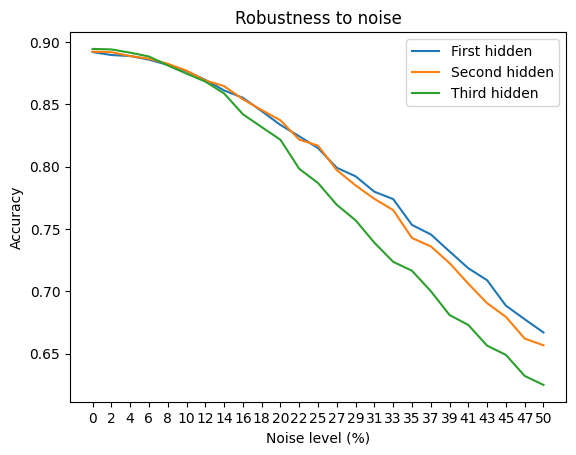

In [47]:
noise_levels = np.linspace(0.0, 0.5, 25)
plot_noise_robustness_curves(noise_levels)

We can see that there is a large difference in the robustness to noise between the layers. All three hidden layers start at fairly high accuracies but as more noise is added deeper layers decrease faster then shallower ones. This suggests that even though deeper layers have higher accuracy initially they are influenced a lot by noise. This has to do with the fact that the deeper layers rally on input from the shallower layers so they take and increase the errors from the layer bellow them.

We can also see that all three layers do fairly well with noise, even when 50% of the image is noise I get more then 65% accuracy for each layer. This indicates that the model is not overfitting to the data and is instead learning. This may be due to my regularization strategy such as using weight decay and patience when i was training my linear model as well as batch normalization.

# **Adversarial attacks and few shots learning**

**Adversarial attacks**

I'm using the fast gradient sign method for adversarial attacks. Basically I am taking a image-target pair ,calculating the loss with respect to the input ,and getting the gradient, i am then adding epsilon in the direction of the sign of the gradient to the image. The gradient sign tells us exactly the direction the image should be altered in order to best deceive the model.

In [48]:
test_loader = torch.utils.data.DataLoader(
    tv.datasets.FashionMNIST('data/', train=False, download=True, transform=tv.transforms.Compose([tv.transforms.ToTensor()])),
    batch_size=100, shuffle=True)

def fgsm_attack(image, epsilon, data_grad):
    sign_data_grad = data_grad.sign()
    perturbed_image = image + epsilon * sign_data_grad
    perturbed_image = torch.clamp(perturbed_image, 0, 1)
    return perturbed_image


class DBNWithReadOut(torch.nn.Module):
    def __init__(self, dbn_mnist, readout):
        super().__init__()
        self.readout = readout
        self.readout_level = 2
        self.dbn_mnist = dbn_mnist
        self._require_grad()

    def _require_grad(self):
      for rbm in self.dbn_mnist.rbm_layers:
        rbm.W.requires_grad_()
        rbm.h_bias.requires_grad_()

    def forward(self, image):
      p_v = image
      hidden_states = []
      for rbm in self.dbn_mnist.rbm_layers:
        p_v = p_v.view((p_v.shape[0], -1))
        p_v, v = rbm(p_v)
        hidden_states.append(p_v)
      return self.readout.forward(hidden_states[self.readout_level])


dbn_with_readout3 = DBNWithReadOut(dbn_fashion_mnist, linear3)
dbn_with_readout2 = DBNWithReadOut(dbn_fashion_mnist, linear2)
dbn_with_readout2 = DBNWithReadOut(dbn_fashion_mnist, linear1)


100%|██████████| 26.4M/26.4M [00:02<00:00, 12.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.77MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 14.2MB/s]


<>:77: SyntaxWarning: invalid escape sequence '\e'
<>:77: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipython-input-3678970668.py:77: SyntaxWarning: invalid escape sequence '\e'
  __ = ax.set_xlabel("Strength of adversarial attack ($\epsilon$)")


  0%|          | 0/100 [00:00<?, ?it/s]


Epsilon: 0
Test Accuracy: 61.42%



  0%|          | 0/100 [00:00<?, ?it/s]


Epsilon: 0.05
Test Accuracy: 47.36%



  0%|          | 0/100 [00:00<?, ?it/s]

... (47 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]


Epsilon: 0.25
Test Accuracy: 11.06%



  0%|          | 0/100 [00:00<?, ?it/s]


Epsilon: 0.3
Test Accuracy: 7.80%



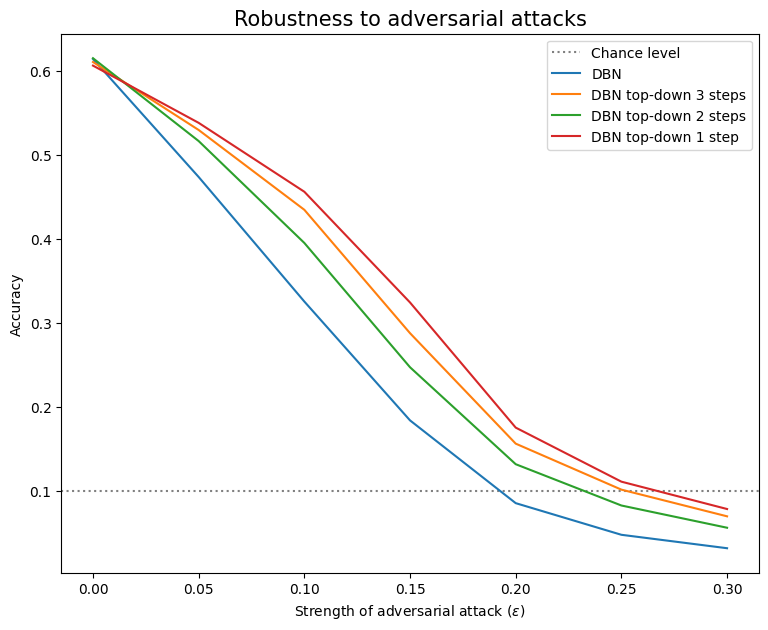

In [54]:

def test_robustness_to_attack(model, device, test_loader, epsilon, num_steps=0, verbose=True):
    correct = 0
    print_reconstruction = num_steps > 0

    for data, target in tqdm(test_loader):
        data, target = data.to(device), target.to(device)
        data = data.reshape(-1, 784)
        data.requires_grad = True

        output = model.forward(data)

        init_pred = torch.argmax(output)

        if (print_reconstruction and verbose):
          print("\nHere's the original sample:\n")
          plt.imshow(data[0].detach().to('cpu').numpy().reshape(28,28))
          plt.show()

        loss_value = torch.nn.functional.cross_entropy(output, target)
        model.zero_grad()
        loss_value.backward()
        data_grad = data.grad.data
        perturbed_data = fgsm_attack(data, epsilon, data_grad)

        if (print_reconstruction and verbose):
            print("\nHere's a perturbed sample:\n")
            plt.imshow(perturbed_data[0].detach().to('cpu').numpy().reshape(28,28))
            plt.show()

        # If requested, reconstruct the input iterating bottom-up and top-down sampling
        if num_steps > 0:
            for __ in range(0, num_steps):
                perturbed_data, __ = model.dbn_mnist.reconstruct(perturbed_data)
            if (print_reconstruction and verbose):
                print(f"\nHere's what a {num_steps}-steps reconstructed sample looks like:\n")
                plt.imshow(perturbed_data[0].detach().to('cpu').numpy().reshape(28,28))
                plt.show()
                print_reconstruction = False

        output = model(perturbed_data)

        final_pred = output.max(1, keepdim=True)[1]
        final_pred = output.argmax(-1)
        correct += (final_pred == target).sum()

    final_acc = correct/float(len(test_loader.sampler))
    print("\nEpsilon: {}\nTest Accuracy: {:.2f}%\n".format(epsilon, final_acc*100))

    return final_acc.item()


epsilon_values = [0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30]

def test_epsilon_values_effect(model, n_steps):
  accuracies = list()

  for eps in epsilon_values:
      acc = test_robustness_to_attack(model, device, test_loader, eps, num_steps=n_steps, verbose=False)
      accuracies.append(acc)

  return accuracies

accuracies_dbn_0 = test_epsilon_values_effect(dbn_with_readout3, n_steps=0)
accuracies_dbn_1 = test_epsilon_values_effect(dbn_with_readout3, n_steps=2)
accuracies_dbn_onestep = test_epsilon_values_effect(dbn_with_readout3, n_steps=1)
accuracies_dbn_3 = test_epsilon_values_effect(dbn_with_readout3, n_steps=3)


fig, ax = plt.subplots(1, 1, figsize=(9, 7), sharey=True)

__ = ax.axhline(0.1, color='gray', linestyle=':')
__ = ax.plot(epsilon_values, accuracies_dbn_0)
__ = ax.plot(epsilon_values, accuracies_dbn_1)
__ = ax.plot(epsilon_values, accuracies_dbn_onestep)
__ = ax.plot(epsilon_values, accuracies_dbn_3)

__ = ax.set_xlabel("Strength of adversarial attack ($\epsilon$)")
__ = ax.set_ylabel("Accuracy")
__ = ax.set_title("Robustness to adversarial attacks", {'fontsize': 15})
__ = ax.legend(["Chance level", "DBN", "DBN top-down 3 steps", "DBN top-down 2 steps", "DBN top-down 1 step"])



The blue line shows the DBNs ability to deal with adversarial attacks. We can see that the DBN accuracy falls fast as we increase the strength of the attack getting closer and closer towards random chance (0.10).

One way to help maintain accuracy against these adversarial attacks is by using DBN's ability to reconstruct the input iterating between top-down and bottom-up sampling. As we can see from the graph I did top-down 3 step, top-down 2 step and top-down 1 step where the step size refers to the number of sampling cycles. This heped the model to maintain some of its accuracy.  It appears that by increasing the number of top-down steps we are increasing the models ability to handle adversarial attacks, especially if the strength is small. As the strength of the attack increases the adversarial noise becomes too much and it is difficult for the top-down steps to defend against.


**few-shot learning**

I am doing prototypical few shot learning and comparing across layers. I am using this to compare how well a model is able to categorize data when there are not a lot of examples. Basically I am taking the first few shot examples for each class in training, averaging them out and then computing the euclidean distance between them and the test examples, the class with the closest euclidean distance to the test example is chosen. The accuracy is then calculated as the amount that the model got correct.

In [50]:
shots = [1,3, 5, 7, 10,15,20]
loader1 = DataLoader(TensorDataset(hidden_repr_1_test, fashion_mnist_te.targets), batch_size=128,shuffle=True)
loader2 = DataLoader(TensorDataset(hidden_repr_2_test, fashion_mnist_te.targets), batch_size=128,shuffle=True)
loader3 = DataLoader(TensorDataset(hidden_repr_3_test, fashion_mnist_te.targets), batch_size=128,shuffle=True)

In [51]:
def few_shot_learning(model, layer, shots, loader):

    True_vals = 0
    model.eval()

    train_images = fashion_mnist_tr.data.float().to(device)
    train_targets = fashion_mnist_tr.targets.to(device)

    all_features = [hidden_repr_1, hidden_repr_2, hidden_repr_3][layer]

    prototypes = []
    for class_num in range(10):
        class_features = all_features[train_targets == class_num][:shots]
        prototype= class_features.mean(dim=0)
        prototypes.append(prototype)

    prototypes = torch.stack(prototypes)

    for test_image, test_target in loader:
        test_image = test_image.float().to(device)
        test_target = test_target.to(device)

        with torch.no_grad():
            test_features = test_image
            distances = torch.cdist(test_features, prototypes)
            pred = distances.argmin(dim=1)

            True_vals += (pred == test_target).sum().item()

    return True_vals / len(loader.dataset) * 100

In [52]:
def plot_few_shot_learning(shots):
    fsl_values_first_hidden = []
    fsl_values_second_hidden = []
    fsl_values_third_hidden = []


    for shot in shots:
        fsl_values_first_hidden.append(few_shot_learning(linear1, 0, shot, loader1))
        fsl_values_second_hidden.append(few_shot_learning(linear2, 1, shot, loader2))
        fsl_values_third_hidden.append(few_shot_learning(linear3, 2, shot, loader3))

    fig, ax = plt.subplots()
    ax.plot(shots, fsl_values_first_hidden)
    ax.plot(shots, fsl_values_second_hidden)
    ax.plot(shots, fsl_values_third_hidden)

    ax.set_title("Few Shot Learning Accuracy")
    ax.set_xlabel("Number of Shots")
    ax.set_ylabel("Accuracy")
    plt.legend(["First hidden", "Second hidden", "Third hidden"])

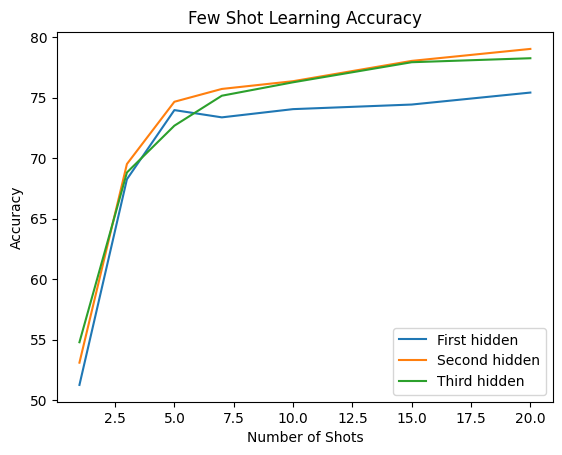

In [53]:
plot_few_shot_learning(shots)


We can see from this graph that all three layers are able to recover a lot of their accuracy by about the 5-shot mark. Even with just 1-shot all three layers are able to get over 50% accuracy, which shows the DBN does very well with few shot learning. As the layers get deeper they have better accuracy with few-shot learning, this is likely due to the fact that deeper layers are less sensitive to variations in the images, and the fact that deeper layers are more disentangled so finding the nearest class is easier.